In [1]:
import pandas as pd
import numpy as np
from src.data_preprocessing import preprocess
from src.hourly_grouping import build_session_hours
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

import warnings
warnings.filterwarnings("ignore")

In [2]:
df_raw = pd.read_csv("datasets/EVChargingStationUsage.csv")
df = preprocess(df_raw)
df.head(2)

[IDs -> strings]
[parse dates, drop invalid]
  dropped 249 rows with invalid or missing dates
[drop non-USD sessions and redundant columns]
  dropped 14 rows with currency MXN, EUR, CAD
  dropped columns: ['Country', 'Plug Type', 'Org Name', 'Currency', 'City', 'State/Province']
[clean station names]
[clean addresses]
[normalize MAC addresses]
[fill EVSE ID / Model Number from MAC]
  EVSE ID: filled 57,688 of 78,927 missing, 21,239 still missing
  Model Number: filled 57,688 of 78,927 missing, 21,239 still missing
[drop System S/N]
[fill missing categoricals with 'missing']
[add UTC columns]
[drop time zone mismatches]
  dropped 120 rows where start and end time zones are different
[validate durations and build duration columns]
  dropped 347 rows with missing or inconsistent duration (difference > 60 s)
[add time features]
[check Start <= End]
  OK: no rows with Start Date later than End Date
[remove outliers]
Sessions kept: 256,643 of 258,685 (failed plug-ins removed: 2,024, impossib

,Station Name,MAC Address,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),Energy (kWh),...,total_duration_hours,charging_duration_hours,idle_seconds,idle_hours,start_hour,time_of_day,year,month,day_of_week,site
0,HAMILTON 1,000D6F00015A9D76,2011-07-29 20:17:00,PDT,2011-07-29 23:20:00,PDT,2011-07-29 23:20:00,3:03:32,1:54:03,6.249457,...,3.058889,1.900833,4169.0,1.158056,20,Evening,2011,7,4,HAMILTON
1,HAMILTON 1,000D6F00015A9D76,2011-07-30 00:00:00,PDT,2011-07-30 00:02:00,PDT,2011-07-30 00:02:00,0:02:06,0:01:54,0.106588,...,0.035000,0.031667,12.0,0.003333,0,Night,2011,7,5,HAMILTON


## Hourly intervals (from src/hourly_grouping)

In [3]:
hourly_events = build_session_hours(df)
hourly_events.head(10)

Hourly rows: 896,991 (on average 3.5 hours per session)


,session_id,User ID,Station Name,hour,occupied_h,charging_h,energy_kwh,idle_h
0,0,3284,HAMILTON 1,2011-07-29 20:00:00,0.716667,0.716667,2.356218,0.000000
1,0,3284,HAMILTON 1,2011-07-29 21:00:00,1.000000,1.000000,3.287746,0.000000
2,0,3284,HAMILTON 1,2011-07-29 22:00:00,1.000000,0.184167,0.605493,0.815833
3,0,3284,HAMILTON 1,2011-07-29 23:00:00,0.342222,0.000000,0.000000,0.342222
4,1,4169,HAMILTON 1,2011-07-30 00:00:00,0.035000,0.031667,0.106588,0.003333
5,2,4169,HAMILTON 1,2011-07-30 08:00:00,0.733333,0.733333,2.555198,0.000000
6,2,4169,HAMILTON 1,2011-07-30 09:00:00,1.000000,1.000000,3.484360,0.000000
7,2,4169,HAMILTON 1,2011-07-30 10:00:00,1.000000,1.000000,3.484360,0.000000
8,2,4169,HAMILTON 1,2011-07-30 11:00:00,1.000000,1.000000,3.484360,0.000000
9,2,4169,HAMILTON 1,2011-07-30 12:00:00,0.558889,0.557778,1.943499,0.001111


#### Quick analysus if the first sessions

First row from df - Hammilton 1, Start Date 2011-07-29 20:17, total duration sec 11012 (around 3h), charging duration 6843 (around 2h), energy 6.25. Then end of the charging would be 20:17 + 6843s = 22:11

20-21 (only 43 min = 0.71h) 

21- 22 (whole hour)

22-23 (only 11 min = 0.18h)

23-24 (only plugged in but not charging)

## User table - time preferences

In [4]:
def build_user_features(session_hours: pd.DataFrame, min_sessions: int = 10, verbose: bool = True) -> pd.DataFrame:
    blocks = ["night", "morning", "afternoon", "evening"]

    # 1. unknown users are not individual users
    unknown = session_hours["User ID"].isna() | session_hours["User ID"].isin(["missing", "0"])
    sh = session_hours.loc[~unknown].copy()

    # 2. keep users with enough sessions
    sessions_per_user = sh.groupby("User ID")["session_id"].nunique()
    keep = sessions_per_user[sessions_per_user >= min_sessions].index
    sh = sh[sh["User ID"].isin(keep)].copy()

    # 3. timing: share of energy in each part of the day (hourly rows)
    sh["time_block"] = pd.cut(sh["hour"].dt.hour, [-1, 5, 11, 17, 23], labels=blocks)
    energy_total = sh.groupby("User ID")["energy_kwh"].sum()
    energy_by_block = (
        sh.groupby(["User ID", "time_block"], observed=False)["energy_kwh"].sum().unstack(fill_value=0)
    )
    shares = energy_by_block.div(energy_total, axis=0).add_prefix("share_energy_")
    # night is dropped: almost nobody charges at night (extremely skewed), and its share is
    # implied by the other three (night = 1 - morning - afternoon - evening)
    shares = shares.drop(columns="share_energy_night")

    # share of energy on Saturday and Sunday
    is_weekend = sh["hour"].dt.dayofweek >= 5
    energy_weekend = sh[is_weekend].groupby("User ID")["energy_kwh"].sum().reindex(energy_total.index, fill_value=0)
    shares["share_energy_weekend"] = energy_weekend / energy_total

    # 4. back to one row per session: typical charging and idle time, in minutes
    sess = sh.groupby("session_id").agg(
        user=("User ID", "first"),
        charging_h=("charging_h", "sum"),
        occupied_h=("occupied_h", "sum"),
    )
    sess["charging_min"] = sess["charging_h"] * 60
    sess["idle_min"] = (sess["occupied_h"] - sess["charging_h"]) * 60
    by_user = sess.groupby("user")

    features = shares.join(pd.DataFrame({
        "median_charging_min": by_user["charging_min"].median(),
        "median_idle_min": by_user["idle_min"].median(),
    }))
    features.index.name = "User ID"

    if verbose:
        print(f"Users with at least {min_sessions} sessions: {len(keep):,} "
              f"({len(keep) / len(sessions_per_user):.0%} of known users, "
              f"{sessions_per_user[keep].sum() / sessions_per_user.sum():.0%} of their sessions)")
        print(f"User features: {features.shape[0]:,} users x {features.shape[1]} features, "
              f"missing values: {int(features.isna().sum().sum())}")
    return features

In [5]:
user_features1 = build_user_features(hourly_events, min_sessions=10, verbose=True)
user_features1.head(3)

Users with at least 10 sessions: 3,579 (17% of known users, 84% of their sessions)
User features: 3,579 users x 6 features, missing values: 0


,share_energy_morning,share_energy_afternoon,share_energy_evening,share_energy_weekend,median_charging_min,median_idle_min
User ID,,,,,,
100243,0.079066,0.220512,0.607114,0.269483,143.666667,4.416667
100293,0.593211,0.038918,0.367870,0.613430,115.583333,33.233333
100523,0.124016,0.770184,0.105800,0.080989,94.441667,0.400000


## User table - intensity
(Experiments with different alternatives)

In [6]:
def build_user_features2(session_hours: pd.DataFrame,
                          min_sessions: int = 10,
                          verbose: bool = True) -> pd.DataFrame:

    # 1. Remove unknown users
    unknown = (
        session_hours["User ID"].isna() |
        session_hours["User ID"].isin(["missing", "0"])
    )
    sh = session_hours.loc[~unknown].copy()

    # 2. Keep users with enough sessions
    sessions_per_user = sh.groupby("session_id")["User ID"].first()
    sessions_per_user = sessions_per_user.value_counts()
    keep = sessions_per_user[sessions_per_user >= min_sessions].index
    sh = sh[sh["User ID"].isin(keep)].copy()

    # 3. One row per session
    sess = sh.groupby("session_id").agg(
        user=("User ID", "first"),
        charging_h=("charging_h", "sum"),
        energy_kwh=("energy_kwh", "sum")
    )

    # 4. Aggregate per user
    by_user = sess.groupby("user")

    features = pd.DataFrame({
        "n_sessions": by_user.size(),
        "total_energy_kwh": by_user["energy_kwh"].sum(),
        "median_energy_per_session": by_user["energy_kwh"].median(),
        "median_charging_min": by_user["charging_h"].median() * 60})

    features.index.name = "User ID"

    if verbose:
        print(f"Users with at least {min_sessions} sessions: {len(keep):,}")
        print(f"User features A: {features.shape[0]:,} users x "
              f"{features.shape[1]} features, missing values: "
              f"{int(features.isna().sum().sum())}")

    return features

In [7]:
user_features2 = build_user_features2(hourly_events, min_sessions=10)
user_features2.head(3)

Users with at least 10 sessions: 3,579
User features A: 3,579 users x 4 features, missing values: 0


,n_sessions,total_energy_kwh,median_energy_per_session,median_charging_min
User ID,,,,
100243,649,5322.069112,7.407287,143.666667
100293,15,96.191890,6.336164,115.583333
100523,40,315.634840,7.343470,94.441667


## User table 3 - effectiveness

In [9]:
def build_user_features3(session_hours: pd.DataFrame,
                          min_sessions: int = 10,
                          verbose: bool = True) -> pd.DataFrame:

    # 1. Remove unknown users
    unknown = (
        session_hours["User ID"].isna() |
        session_hours["User ID"].isin(["missing", "0"])
    )
    sh = session_hours.loc[~unknown].copy()

    # 2. Keep users with enough sessions
    sessions_per_user = sh.groupby("session_id")["User ID"].first()
    sessions_per_user = sessions_per_user.value_counts()
    keep = sessions_per_user[sessions_per_user >= min_sessions].index
    sh = sh[sh["User ID"].isin(keep)].copy()

    # 3. One row per session
    sess = sh.groupby("session_id").agg(
        user=("User ID", "first"),
        charging_h=("charging_h", "sum"),
        occupied_h=("occupied_h", "sum"),
        idle_h=("idle_h", "sum")
    )

    # Convert to minutes
    sess["charging_min"] = sess["charging_h"] * 60
    sess["occupied_min"] = sess["occupied_h"] * 60
    sess["idle_min"] = sess["idle_h"] * 60

    # Session-level ratios
    sess["charging_ratio"] = (
        sess["charging_h"] /
        sess["occupied_h"].replace(0, np.nan)
    )

    sess["idle_ratio"] = (
        sess["idle_h"] /
        sess["occupied_h"].replace(0, np.nan)
    )

    # 4. Aggregate per user
    by_user = sess.groupby("user")

    features = pd.DataFrame({
        "median_charging_min": by_user["charging_min"].median(),
        

        "median_occupied_min": by_user["occupied_min"].median(),
       

        "median_idle_min": by_user["idle_min"].median(),
        

        "median_charging_ratio": by_user["charging_ratio"].median(),
       
        "median_idle_ratio": by_user["idle_ratio"].median(),
        
    })

    features.index.name = "User ID"

    if verbose:
        print(f"Users with at least {min_sessions} sessions: {len(keep):,}")
        print(f"User features B: {features.shape[0]:,} users x "
              f"{features.shape[1]} features, missing values: "
              f"{int(features.isna().sum().sum())}")

    return features

In [10]:
user_features3 = build_user_features3(hourly_events, min_sessions=10)
user_features3.head(3)

Users with at least 10 sessions: 3,579
User features B: 3,579 users x 5 features, missing values: 0


,median_charging_min,median_occupied_min,median_idle_min,median_charging_ratio,median_idle_ratio
User ID,,,,,
100243,143.666667,176.733333,4.416667,0.971761,0.028239
100293,115.583333,156.633333,33.233333,0.773678,0.226322
100523,94.441667,99.258333,0.400000,0.995909,0.004091


## All clustering experiments 

In this part I am using 3 datasets that I have prepared to train multiple clustering algorithms with multiple hyperaparameters and exam their results to then pick the best one to move forward.

In [12]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.model_selection import ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

MODEL_GRIDS = {
    "KMeans": {
        "model": KMeans,
        "fixed": {"n_init": 20, "random_state": 42},
        "grid": {"n_clusters": list(range(4, 7))},
    },
    "Hierarchical": {
        "model": AgglomerativeClustering,
        "fixed": {},
        "grid": {"linkage": ["ward", "average"], "n_clusters": list(range(4, 7))},
    },
    "DBSCAN": {
        "model": DBSCAN,
        "fixed": {},
        "grid": {"eps": [0.5,  1.0, 1.5], "min_samples": [5, 10]},
    },
}

PARAM_SHORT = {"n_clusters": "k", "min_samples": "min", "eps": "eps"}
METRICS = ["silhouette", "davies_bouldin", "n_clusters", "noise_%", "largest_%"]


def prepare_features(dataset, log_features):
    """Scaling and log transforming features for clustering."""
    X = dataset.copy()
    X[log_features] = np.log1p(X[log_features])
    X = pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=X.columns)
    assert not X.isna().any().any(), "są braki w cechach"
    return X


def _param_label(params):
    parts = [v if k == "linkage" else f"{PARAM_SHORT.get(k, k)}={v}" for k, v in params.items()]
    return ", ".join(parts)


def _score_labels(X, labels):
    labels = np.asarray(labels)
    core = labels != -1
    Xc, lc = X[core], labels[core]
    n_clusters = len(np.unique(lc))
    out = {
        "silhouette": np.nan,
        "davies_bouldin": np.nan,
        "n_clusters": n_clusters,
        "noise_%": 100 * (1 - core.mean()),
        "largest_%": 100 * pd.Series(lc).value_counts().max() / len(labels) if len(lc) else np.nan,
    }
    if 2 <= n_clusters < len(lc):
        out["silhouette"] = silhouette_score(Xc, lc)
        out["davies_bouldin"] = davies_bouldin_score(Xc, lc)
    return out


def _top3_green(row):
    top = row.rank(ascending=False, method="min") <= 3
    return ["background-color: green; font-weight: bold;" if t else "" for t in top]


def compare_clustering(datasets, model_grids=MODEL_GRIDS, show=True):
    rows = []
    for ds_name, (data, log_features) in datasets.items():
        X = prepare_features(data, log_features).to_numpy()
        for algo, cfg in model_grids.items():
            for params in ParameterGrid(cfg["grid"]):
                labels = cfg["model"](**cfg["fixed"], **params).fit_predict(X)
                rows.append({"dataset": ds_name, "algorithm": algo,
                             "params": _param_label(params), **_score_labels(X, labels)})
    long = pd.DataFrame(rows)
    col_order = pd.MultiIndex.from_frame(long[["algorithm", "params"]].drop_duplicates())
    row_order = pd.MultiIndex.from_product([list(datasets), METRICS], names=["dataset", "metric"])

    def _pivot(metric):
        return (long.pivot(index="dataset", columns=["algorithm", "params"], values=metric)
                    .reindex(index=list(datasets), columns=col_order))

    sil_table, db_table = _pivot("silhouette"), _pivot("davies_bouldin")

    summary = (long.melt(id_vars=["dataset", "algorithm", "params"], value_vars=METRICS, var_name="metric")
                   .pivot(index=["dataset", "metric"], columns=["algorithm", "params"], values="value")
                   .reindex(index=row_order, columns=col_order))

   

    styled = None
  
    idx = pd.IndexSlice
    styled = summary.style.format("{:.3f}", na_rep="–")
    for ds in datasets:
        sil = idx[[(ds, "silhouette")], :]
        info = idx[[(ds, "n_clusters"), (ds, "noise_%"), (ds, "largest_%")], :]
        styled = (styled
                    .apply(_top3_green, axis=1, subset=sil)
                    .format("{:.0f}", subset=idx[[(ds, "n_clusters")], :], na_rep="–")
                    .format("{:.1f}", subset=idx[[(ds, "noise_%"), (ds, "largest_%")], :], na_rep="–")
                    .set_properties(subset=info, **{"color": "grey"}))
    styled = (styled
                .set_caption("Green : 3 best scores in each row")
                .set_table_styles([{"selector": "th.col_heading", "props": "text-align: center;"},
                                    {"selector": "caption", "props": "caption-side: top; font-weight: bold;"}]))

    if show:
        if styled is not None:
            display(styled)
        else:
            
            display(sil_table.round(3))
           
            display(db_table.round(3))
            
            display(summary.loc[pd.IndexSlice[:, ["n_clusters", "noise_%", "largest_%"]], :].round(1))

    return {"long": long, "silhouette": sil_table, "davies_bouldin": db_table,
            "summary": summary, "styled": styled}


DATASETS = {
    "1 · time preferences": (user_features1, ["median_idle_min", "median_charging_min"]),
    "2 · intensity": (user_features2, ["total_energy_kwh", "median_energy_per_session", "median_charging_min"]),
    "3 · effectiveness": (user_features3, ["median_charging_min", "median_occupied_min", "median_idle_min",
                                            "median_idle_ratio"]),
}

comparison = compare_clustering(DATASETS)

## Comment : 
The best clusters based on the silhouette trun out to be just one major cluster with numerous tiny clusters (probably with noise). Therefore we will continue with KMeans. This behavior suggests that users do not form very strict and different behavior clusters but rather smoothly go from one to another. Then KMeans is better at just segmenting the users as well as possible so we can further inspect the clusters for additional differences.

# K - Means on dataset number 3

Data preparation : log and Scaling

In [39]:
def K_means(dataset, LOG_FEATURES):
    X_raw = dataset.copy()
    print("Skewness before:", X_raw.skew().round(2).to_dict())
    X_raw[LOG_FEATURES] = np.log1p(X_raw[LOG_FEATURES])
    print("Skewness after log1p:", X_raw[LOG_FEATURES].skew().round(2).to_dict())

    scaler = StandardScaler()
    X = pd.DataFrame(scaler.fit_transform(X_raw), index=X_raw.index, columns=X_raw.columns)
    assert not X.isna().any().any(), "missing values in features"
    print("Input to K-means:", X.shape)

    K_RANGE = range(2, 11)

    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
        rows.append({
            "k": k,
            "inertia": km.inertia_,
            "silhouette": silhouette_score(X, km.labels_),
            "davies_bouldin": davies_bouldin_score(X, km.labels_),
        })

    k_scores = pd.DataFrame(rows).set_index("k")
    display(k_scores.round(3))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (col, title) in zip(axes, [
        ("inertia", "Inertia "),
        ("silhouette", "Silhouette "),
        ("davies_bouldin", "Davies-Bouldin "),
    ]):
        ax.plot(k_scores.index, k_scores[col], marker="o")
        ax.set_title(title)
        ax.set_xlabel("K")
        ax.grid(True, alpha=0.3)
    sns.despine()
    plt.tight_layout()
    plt.show()

    return {
        "X_scaled": X,
        "X_transformed": X_raw,
        "scaler": scaler,
        "scores": k_scores
    }



In [40]:

def analyze_clusters(results, features_raw, K):
    
    # Scaled features from the previous function
    X_FINAL = results["X_scaled"]

    # Original features for cluster interpretation
    FEATURES = features_raw.loc[X_FINAL.index].copy()

    # Fit final K-means
    km_final = KMeans(
        n_clusters=K,
        n_init=50,
        random_state=42
    ).fit(X_FINAL)

    # Cluster labels
    labels = pd.Series(
        km_final.labels_,
        index=X_FINAL.index,
        name="Cluster"
    )

    # Centroids
    centroids = pd.DataFrame(
        km_final.cluster_centers_,
        columns=X_FINAL.columns
    ).rename_axis("klaster")

    # Metrics
    metrics = {
        "K": K,
        "silhouette": silhouette_score(X_FINAL, labels),
        "davies_bouldin": davies_bouldin_score(X_FINAL, labels),
        "inertia": km_final.inertia_
    }

    # Cluster profiles using original features
    prof = FEATURES.join(labels).groupby("Cluster").median()

    prof.insert(
        0,
        "users",
        labels.value_counts().sort_index()
    )

    prof.insert(
        1,
        "share_%",
        (100 * prof["users"] / prof["users"].sum()).round(1)
    )

    prof = prof.round(2)

    # Print metrics and profile
    print(f"--- K={K} ---")
    print(f"Silhouette: {metrics['silhouette']:.3f}")
    print(f"Davies-Bouldin: {metrics['davies_bouldin']:.3f}")
    print(f"Inertia: {metrics['inertia']:.2f}")

    display(prof)

    # Plot centroids
    fig, ax = plt.subplots(figsize=(10, 4))

    sns.heatmap(
        centroids,
        cmap="RdBu_r",
        center=0,
        annot=True,
        fmt=".2f",
        linewidths=0.5,
        ax=ax,
        cbar=False
    )

    ax.set_title(f"K={K} (z-score cech)")
    ax.set_ylabel("klaster")
    ax.tick_params(axis="x", rotation=35)

    plt.tight_layout()
    plt.show()

    return {
        "model": km_final,
        "labels": labels,
        "centroids": centroids,
        "profile": prof,
        "metrics": metrics
    }


Skewness before: {'median_charging_min': 2.14, 'median_occupied_min': 2.9, 'median_idle_min': 9.25, 'median_charging_ratio': -3.39, 'median_idle_ratio': 3.39}
Skewness after log1p: {'median_charging_min': -0.52, 'median_occupied_min': -0.42, 'median_idle_min': 1.73, 'median_charging_ratio': -3.76, 'median_idle_ratio': 3.0}
Input to K-means: (3579, 5)


,inertia,silhouette,davies_bouldin
k,,,
2,9721.323,0.584,0.773
3,6178.489,0.446,0.750
4,4410.787,0.467,0.733
5,3324.234,0.463,0.709
6,2797.759,0.461,0.790
7,2380.375,0.426,0.780
8,2144.671,0.409,0.787
9,1928.937,0.410,0.802
10,1736.600,0.414,0.802


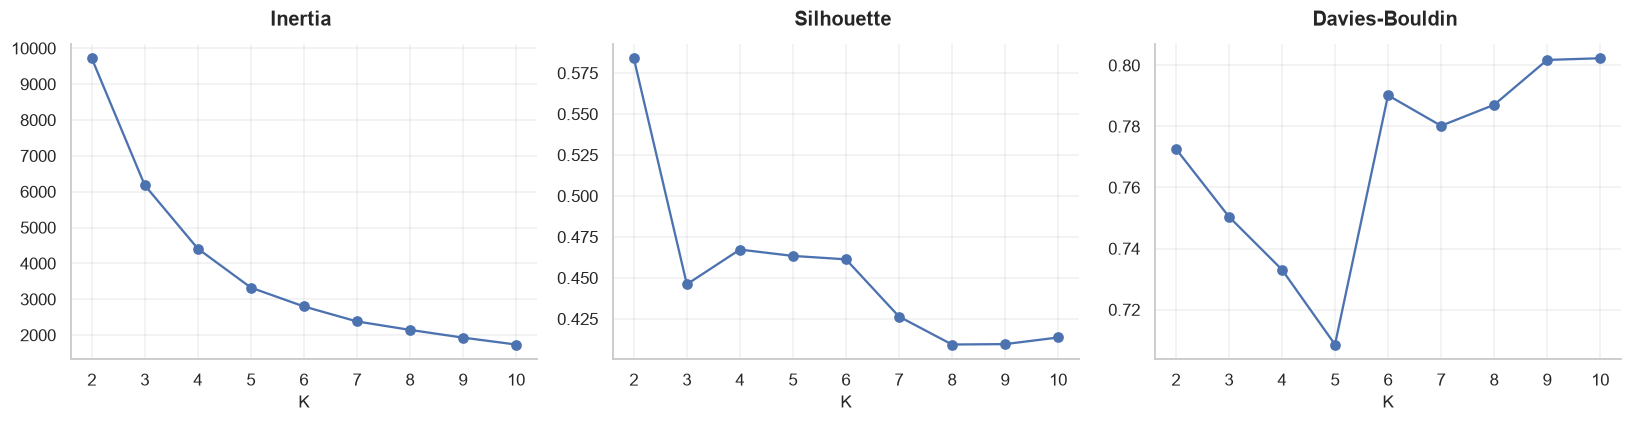

In [41]:
results3 = K_means(user_features3, LOG_FEATURES=[ "median_charging_min",  "median_occupied_min", "median_idle_min","median_charging_ratio",  "median_idle_ratio" ])

I choose K = 5 based on the silhouette and davies

--- K=5 ---
Silhouette: 0.463
Davies-Bouldin: 0.709
Inertia: 3324.21


,users,share_%,median_charging_min,median_occupied_min,median_idle_min,median_charging_ratio,median_idle_ratio
Cluster,,,,,,,
0,1056,29.5,153.34,163.78,0.36,1.00,0.00
1,434,12.1,39.37,42.18,0.30,0.99,0.01
2,149,4.2,99.25,184.62,74.72,0.56,0.44
3,1436,40.1,76.69,82.82,0.32,0.99,0.01
4,504,14.1,127.33,160.10,20.93,0.86,0.14


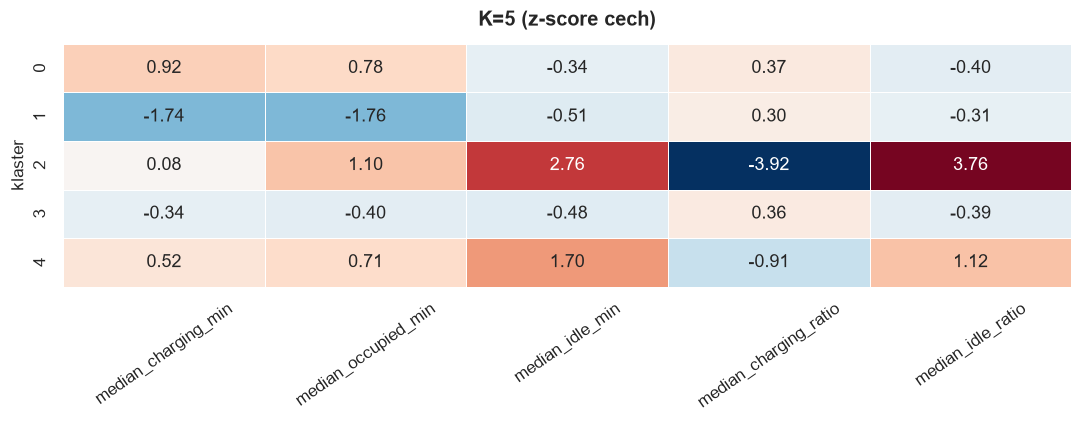

In [42]:
final3 = analyze_clusters(
    results=results3,
    features_raw=user_features3,
    K=5
) 
    

## Best one so far:

Silhouette is quite high and we gained good cluster interpratation.

Cluster 0 : Long but efficient charging. These users charge for quite long, but charging time is mostly equal to total time 

Cluster 1: Short charging sessions with little idle time 

Cluster 2: Average charging time but a lot of idle minutes (idle dominated sessions)

Cluster 3: Regular,moderate users with regular charging time and not high idle minutes

Cluster 4: Long charging sessions with high idle. 

## Continue with cluster 3

In [43]:
labels = final3["labels"].copy()
labels.index = labels.index.astype(str)          

df_cl = df.copy()
df_cl["User ID"] = df_cl["User ID"].astype(str)
df_cl["Cluster"] = df_cl["User ID"].map(labels)  # NaN = user with no cluster



In [44]:
# ---------- shared style for all cluster charts ----------
CLUSTER_NAMES = {
    0: "Long, effective",
    1: "Short sessions",
    2: "Long idle",
    3: "Regular",
    4: "Long charging, long idle",
}
CLUSTER_ORDER = sorted(CLUSTER_NAMES)
CLUSTER_LABELS = {c: f"{c} · {n}" for c, n in CLUSTER_NAMES.items()}
CLUSTER_COLORS = dict(zip(CLUSTER_ORDER, sns.color_palette("Set2", len(CLUSTER_ORDER))))

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})

# clustered sessions only, cluster as int (used by every analysis below)
dc = df_cl[df_cl["Cluster"].notna()].copy()
dc["Cluster"] = dc["Cluster"].astype(int)
dc["Start Date"] = pd.to_datetime(dc["Start Date"])
dc["End Date"] = pd.to_datetime(dc["End Date"])


def cluster_heatmap(table, title, xlabel="", cbar_label="% of cluster sessions", fmt=".0f",
                    cmap="Blues", figsize=None, center=None):
    # Heatmap with clusters as rows: readable names, annotated cells, labelled colour bar.
    figsize = figsize or (min(16, 1.2 * table.shape[1] + 5.5), 0.6 * table.shape[0] + 2)
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(table, annot=True, fmt=fmt, cmap=cmap, center=center, linewidths=1, linecolor="white",
                cbar_kws={"label": cbar_label, "shrink": 0.8}, ax=ax,
                yticklabels=[CLUSTER_LABELS[c] for c in table.index])
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.tick_params(axis="y", rotation=0)
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

## 1. Preffered sites by cluster

Skipped small sites: ['SHERMAN']


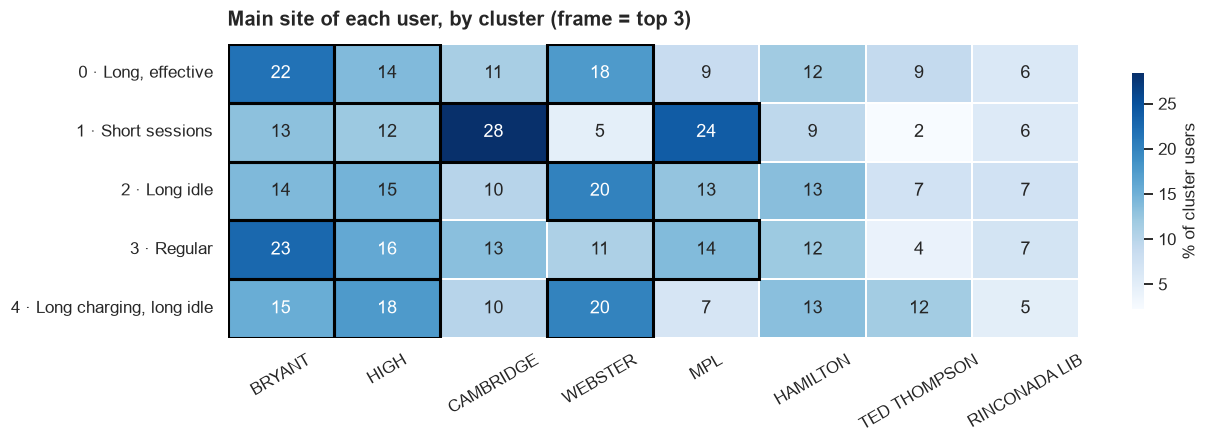

site  % users  % sessions  lift
cluster                      rank                                      
0 · Long, effective          1        BRYANT    21.69       19.82  1.09
                             2       WEBSTER    17.61       16.37  1.27
                             3          HIGH    13.92       16.62  0.92
1 · Short sessions           1     CAMBRIDGE    28.34       25.78  2.03
                             2           MPL    23.96       19.12  1.92
                             3        BRYANT    13.13       11.49  0.66
2 · Long idle                1       WEBSTER    20.13       21.12  1.46
                             2          HIGH    14.77       10.92  0.98
                             3        BRYANT    14.09       17.72  0.71
3 · Regular                  1        BRYANT    22.70       17.61  1.14
                             2          HIGH    16.02       14.88  1.06
                             3           MPL    13.86       15.30  1.11
4 · Long charging, long idle 1       WEBSTER    20.04       18.70  1.45
                             2          HIGH    17.66       14.01  1.17
                             3        BRYANT    15.48       14.54  0.78

In [45]:
TOP_N = 3                # how many sites to show per cluster
MIN_SITE_SHARE = 0.01    # skip sites with < 1% of sessions (e.g. SHERMAN)


def preferred_sites(dc, top_n=TOP_N, min_site_share=MIN_SITE_SHARE, plot=True):
    # 1. drop very small sites
    site_share = dc["site"].value_counts(normalize=True)
    small = site_share[site_share < min_site_share].index.tolist()
    if small:
        print("Skipped small sites:", small)
    d = dc[~dc["site"].isin(small)]

    # 2. each user's main site (the one with most of their sessions)
    per_user_site = d.groupby(["User ID", "site"]).size()
    users = pd.DataFrame({
        "Cluster": d.groupby("User ID")["Cluster"].first(),
        "main_site": per_user_site.groupby(level=0).idxmax().str[1],
        "main_site_share": per_user_site.groupby(level=0).max() / d.groupby("User ID").size(),
    })

    # 3. % of cluster users with a given main site, lift, % of cluster sessions
    site_order = users["main_site"].value_counts().index
    pct_users = pd.crosstab(users["Cluster"], users["main_site"], normalize="index")[site_order] * 100
    lift = pct_users / (users["main_site"].value_counts(normalize=True)[site_order] * 100)
    pct_sessions = pd.crosstab(d["Cluster"], d["site"], normalize="index")[site_order] * 100

    # 4. top-N table
    rows = []
    for c in pct_users.index:
        for rank, site in enumerate(pct_users.loc[c].nlargest(top_n).index, start=1):
            rows.append({"cluster": CLUSTER_LABELS[c], "rank": rank, "site": site,
                         "% users": pct_users.loc[c, site], "% sessions": pct_sessions.loc[c, site],
                         "lift": lift.loc[c, site]})
    top = pd.DataFrame(rows).set_index(["cluster", "rank"]).round(2)

    # 5. heatmap with top-N framed
    if plot:
        fig, ax = plt.subplots(figsize=(12, 4.2))
        sns.heatmap(pct_users, annot=True, fmt=".0f", cmap="Blues", ax=ax, linewidths=1, linecolor="white",
                    cbar_kws={"label": "% of cluster users", "shrink": 0.8},
                    yticklabels=[CLUSTER_LABELS[c] for c in pct_users.index])
        for i, c in enumerate(pct_users.index):
            for site in pct_users.loc[c].nlargest(top_n).index:
                j = pct_users.columns.get_loc(site)
                ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", lw=2))
        ax.set_title(f"Main site of each user, by cluster (frame = top {top_n})", loc="left")
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(axis="x", rotation=30)
        plt.tight_layout()
        plt.show()

    return {"top": top, "pct_users": pct_users.round(1), "lift": lift.round(2),
            "pct_sessions": pct_sessions.round(1), "users": users}


site_pref = preferred_sites(dc)
display(site_pref["top"])

#### Conclusions 
 
 * not a very useful distinction. Webster, High and Bryant seem to be the most preffered across all clusters.

 * Cluster 1 (short sessions) is the only one with a clear preference towards Cambridge and MPL

 * Location is a weak descriptor of the clusters; behavior is a trait of a user, not a station


## 2. Idle time by station and who causes it

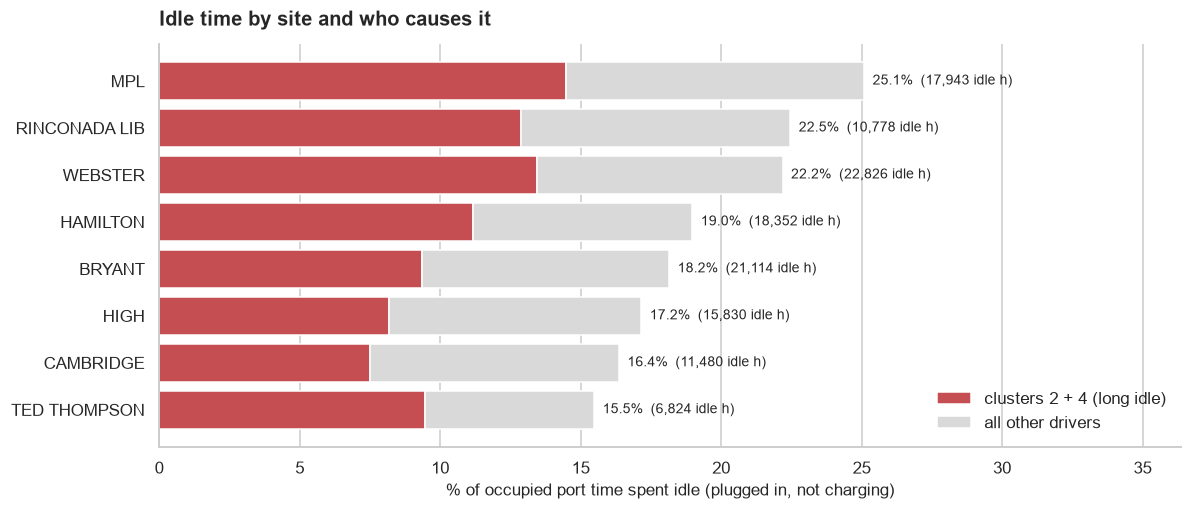

,sessions,occupied_h,idle_h,idle_h_clusters_2_4,% idle of occupied time,% of idle from clusters 2+4
site,,,,,,
MPL,28021,71512.7,17942.8,10361.2,25.1,57.7
RINCONADA LIB,18125,47985.9,10778.4,6184.3,22.5,57.4
WEBSTER,37286,102873.9,22825.7,13823.2,22.2,60.6
HAMILTON,38141,96712.6,18352.2,10816.6,19.0,58.9
BRYANT,46386,116315.1,21113.9,10873.0,18.2,51.5
HIGH,39470,92242.2,15829.6,7538.5,17.2,47.6
CAMBRIDGE,32580,70157.3,11479.8,5259.3,16.4,45.8
TED THOMPSON,16591,44077.7,6824.4,4175.8,15.5,61.2


In [46]:
big_sites = dc["site"].value_counts(normalize=True)
big_sites = big_sites[big_sites >= MIN_SITE_SHARE].index
d_all = df_cl[df_cl["site"].isin(big_sites)]          # all sessions (also users without cluster)
idle_clusters = d_all["Cluster"].isin([2, 4])

site_idle = pd.DataFrame({
    "sessions": d_all.groupby("site").size(),
    "occupied_h": d_all.groupby("site")["total_duration_hours"].sum(),
    "idle_h": d_all.groupby("site")["idle_hours"].sum(),
    "idle_h_clusters_2_4": d_all[idle_clusters].groupby("site")["idle_hours"].sum(),
})
site_idle["% idle of occupied time"] = 100 * site_idle["idle_h"] / site_idle["occupied_h"]
site_idle["% of idle from clusters 2+4"] = 100 * site_idle["idle_h_clusters_2_4"] / site_idle["idle_h"]
site_idle = site_idle.sort_values("% idle of occupied time")

# chart: idle share of occupied time, split into clusters 2+4 vs everyone else
part_24 = site_idle["% idle of occupied time"] * site_idle["% of idle from clusters 2+4"] / 100
part_rest = site_idle["% idle of occupied time"] - part_24

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.barh(site_idle.index, part_24, color="#c44e52", label="clusters 2 + 4 (long idle)")
ax.barh(site_idle.index, part_rest, left=part_24, color="#d9d9d9", label="all other drivers")
for i, site in enumerate(site_idle.index):
    ax.text(site_idle.loc[site, "% idle of occupied time"] + 0.3, i,
            f"{site_idle.loc[site, '% idle of occupied time']:.1f}%  ({site_idle.loc[site, 'idle_h']:,.0f} idle h)",
            va="center", fontsize=9)
ax.set_xlim(0, site_idle["% idle of occupied time"].max() * 1.45)
ax.set_xlabel("% of occupied port time spent idle (plugged in, not charging)")
ax.set_title("Idle time by site and who causes it", loc="left")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

display(site_idle.sort_values("% idle of occupied time", ascending=False).round(1))

### Cocnlusions 

* This plot shows that MLP and Riconda sites have the higest % of idle time. These sites are next to libraries so probably people leave their cars there. 

* Cluster interpratation : We can see that users from clusters 2 and 4 cause the majority of idle time on ALL stations. 

* This illustrates that the problem is present network-wise (and not only on some sites). Therefore local solutions wont be enough

## 3. When do clusters charge?

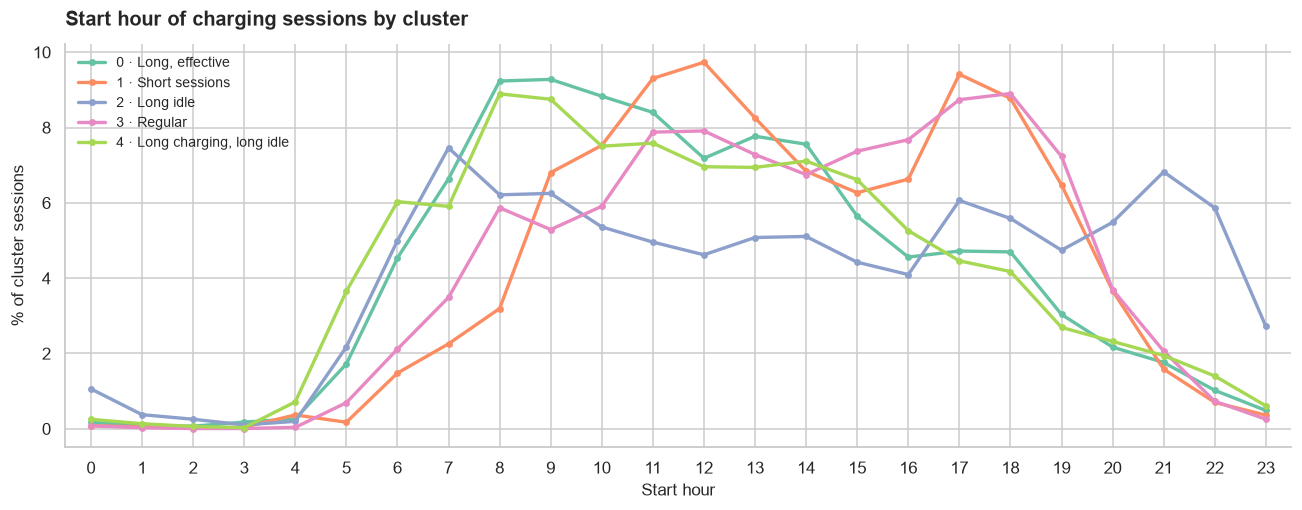

In [47]:
# 3a. start hour: line per cluster (each line sums to 100%)
dc["start_hour"] = dc["Start Date"].dt.hour
hourly_cluster = pd.crosstab(dc["start_hour"], dc["Cluster"], normalize="columns").reindex(range(24), fill_value=0) * 100

fig, ax = plt.subplots(figsize=(12, 4.8))
for c in CLUSTER_ORDER:
    ax.plot(hourly_cluster.index, hourly_cluster[c], marker="o", ms=3.5, lw=2.2,
            color=CLUSTER_COLORS[c], label=CLUSTER_LABELS[c])
ax.set_xticks(range(24))
ax.set_xlim(-0.5, 23.5)
ax.set_xlabel("Start hour")
ax.set_ylabel("% of cluster sessions")
ax.set_title("Start hour of charging sessions by cluster", loc="left")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

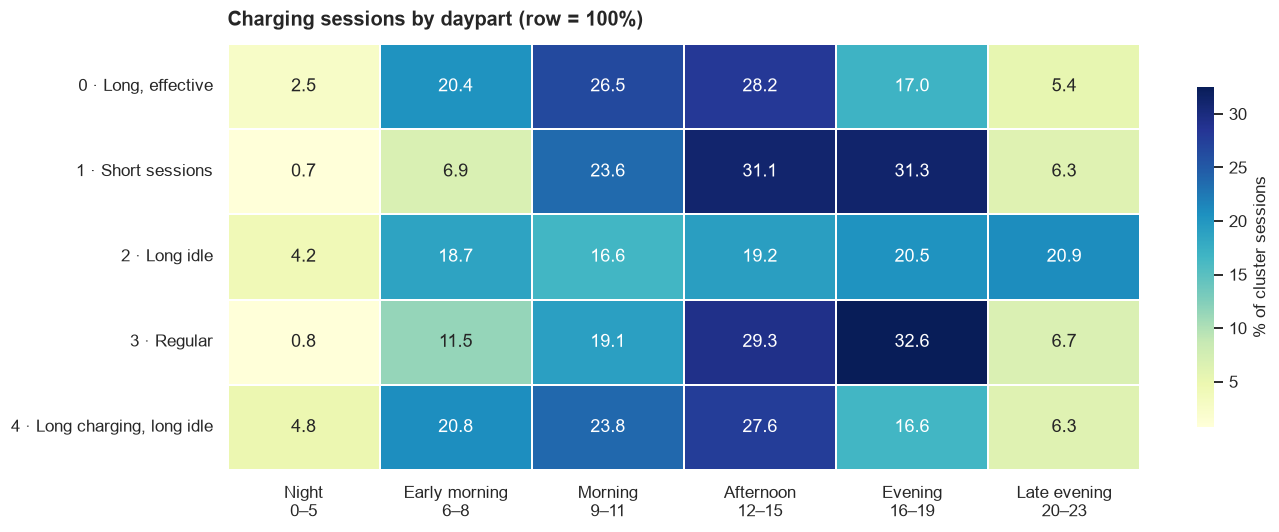

In [48]:
# 3b. dayparts (summary of the chart above)
DAYPART_BINS = [-1, 5, 8, 11, 15, 19, 23]
DAYPARTS = ["Night\n0–5", "Early morning\n6–8", "Morning\n9–11", "Afternoon\n12–15",
            "Evening\n16–19", "Late evening\n20–23"]
dc["daypart"] = pd.cut(dc["start_hour"], DAYPART_BINS, labels=DAYPARTS)
daypart_heatmap = pd.crosstab(dc["Cluster"], dc["daypart"], normalize="index") * 100

cluster_heatmap(daypart_heatmap, "Charging sessions by daypart (row = 100%)", fmt=".1f", cmap="YlGnBu")

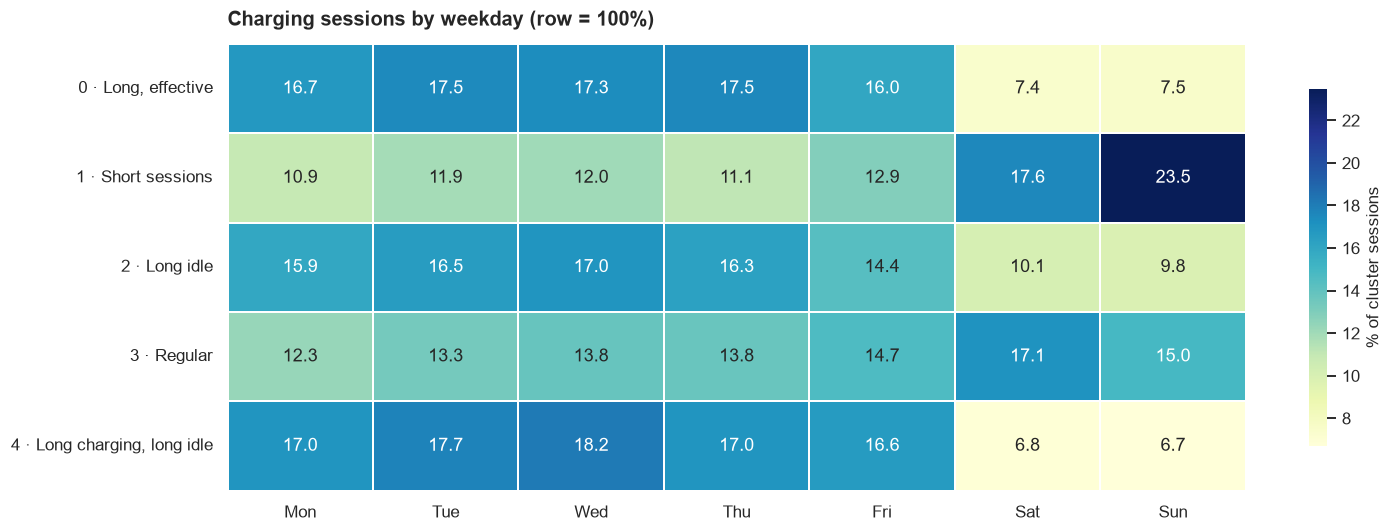

In [49]:
# 3c. weekday
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday_heatmap = pd.crosstab(dc["Cluster"], dc["Start Date"].dt.dayofweek, normalize="index") * 100
weekday_heatmap.columns = WEEKDAYS

cluster_heatmap(weekday_heatmap, "Charging sessions by weekday (row = 100%)", fmt=".1f", cmap="YlGnBu")

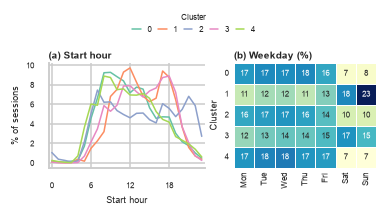

In [50]:
dc["start_hour"] = dc["Start Date"].dt.hour
hourly_cluster = (pd.crosstab(dc["start_hour"], dc["Cluster"], normalize="columns")
                    .reindex(range(24), fill_value=0) * 100)

WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday_heatmap = pd.crosstab(dc["Cluster"], dc["Start Date"].dt.dayofweek, normalize="index") * 100
weekday_heatmap.columns = WEEKDAYS

tiny_fonts = {"font.size": 6, "axes.titlesize": 6.5, "axes.titleweight": "bold",
              "axes.labelsize": 6, "xtick.labelsize": 5.5, "ytick.labelsize": 5.5,
              "legend.fontsize": 5.5, "axes.titlepad": 3}

with plt.rc_context(tiny_fonts):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(3.5, 1.9), gridspec_kw={"width_ratios": [1.1, 1]})

    # (a) start hour
    for c in CLUSTER_ORDER:
        ax1.plot(hourly_cluster.index, hourly_cluster[c], lw=1, color=CLUSTER_COLORS[c], label=str(c))
    ax1.set_xticks(range(0, 24, 6))
    ax1.set_xlim(-0.5, 23.5)
    ax1.set_xlabel("Start hour")
    ax1.set_ylabel("% of sessions")
    ax1.set_title("(a) Start hour", loc="left")

    # (b) weekday
    sns.heatmap(weekday_heatmap, annot=True, fmt=".0f", cmap="YlGnBu", cbar=False,
                linewidths=0.4, linecolor="white", ax=ax2, annot_kws={"size": 5})
    ax2.set_title("(b) Weekday (%)", loc="left")
    ax2.set_xlabel("")
    ax2.set_ylabel("Cluster")
    ax2.tick_params(axis="both", length=0)
    ax2.tick_params(axis="y", rotation=0)
    ax2.tick_params(axis="x", rotation=90)

    handles, labels = ax1.get_legend_handles_labels()
    fig.legend(handles, labels, title="Cluster", ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.0),
               frameon=False, handlelength=1, columnspacing=0.8, title_fontsize=5.5)

    fig.tight_layout(rect=(0, 0, 1, 0.83), w_pad=0.5)
    fig.savefig("figures/when_clusters_charge.pdf", bbox_inches="tight")
    plt.show()

### Conclusions:

Cluster 0 : Weekday users, start most often in the morning

Cluster 1 : Weekend users, mostly sunday, have 2 charging peaks (around 12 and 17), but most of the sessions takes place in the evening/ afternoon

Cluster 2 : Weekday users, quite evenly distributed throughout times of day but with a visible peak at 21 (which can explain the long idle time when leaving the car for the whole evening)

Cluster 3: spread across all days but mostly saturday and sunday, starts charging in the evenings

Cluster 4: Weekday, start primarily in the morning (and maybe leave their car plugged throughout the day)



## 4. Loyalty to one site

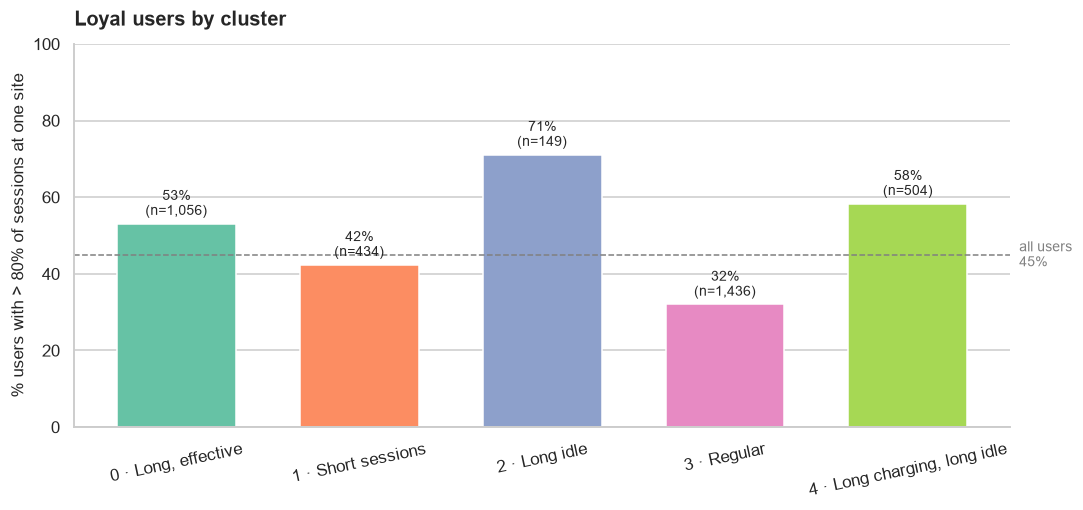

,users,loyal_pct,median_sites
Cluster,,,
"0 · Long, effective",1056,53.1,3.0
1 · Short sessions,434,42.4,3.0
2 · Long idle,149,71.1,2.0
3 · Regular,1436,32.0,3.0
"4 · Long charging, long idle",504,58.3,2.0


In [51]:
station_counts = dc.groupby(["User ID", "Cluster", "site"]).size().reset_index(name="sessions")
station_counts["user_sessions"] = station_counts.groupby("User ID")["sessions"].transform("sum")
station_counts["station_share"] = station_counts["sessions"] / station_counts["user_sessions"]

loyalty = station_counts.groupby(["User ID", "Cluster"]).agg(
    unique_stations=("site", "nunique"),
    top_station_share=("station_share", "max"),
).reset_index()

LOYAL_THRESHOLD = 0.8   # loyal = more than 80% of sessions at one site
loyalty["loyal_customer"] = loyalty["top_station_share"] > LOYAL_THRESHOLD
loyalty_by_cluster = loyalty.groupby("Cluster").agg(
    users=("loyal_customer", "size"),
    loyal_pct=("loyal_customer", lambda x: 100 * x.mean()),
    median_sites=("unique_stations", "median"),
)
overall_loyal = 100 * loyalty["loyal_customer"].mean()

fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.bar([CLUSTER_LABELS[c] for c in loyalty_by_cluster.index], loyalty_by_cluster["loyal_pct"],
              color=[CLUSTER_COLORS[c] for c in loyalty_by_cluster.index], width=0.65)
ax.bar_label(bars, labels=[f"{v:.0f}%\n(n={n:,})" for v, n in
                           zip(loyalty_by_cluster["loyal_pct"], loyalty_by_cluster["users"])],
             padding=3, fontsize=9)
ax.axhline(overall_loyal, ls="--", c="grey", lw=1)
ax.text(1.01, overall_loyal, f"all users\n{overall_loyal:.0f}%", transform=ax.get_yaxis_transform(),
        ha="left", va="center", color="grey", fontsize=9)
ax.set_ylim(0, 100)
ax.set_ylabel(f"% users with > {LOYAL_THRESHOLD:.0%} of sessions at one site")
ax.set_title("Loyal users by cluster", loc="left")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

display(loyalty_by_cluster.rename(index=CLUSTER_LABELS).round(1))

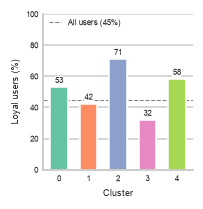

In [38]:
PANEL_W, PANEL_H = 1.7, 1.75
panel_fonts = {"font.size": 6, "axes.labelsize": 6, "xtick.labelsize": 5.5,
               "ytick.labelsize": 5.5, "legend.fontsize": 5.5}

with plt.rc_context(panel_fonts):
    fig, ax = plt.subplots(figsize=(PANEL_W, PANEL_H))
    bars = ax.bar([str(c) for c in loyalty_by_cluster.index], loyalty_by_cluster["loyal_pct"],
                  color=[CLUSTER_COLORS[c] for c in loyalty_by_cluster.index], width=0.6)
    labels = ax.bar_label(bars, labels=[f"{v:.0f}" for v in loyalty_by_cluster["loyal_pct"]],
                          padding=1.5, fontsize=5.5)
    for t in labels:
        t.set_bbox(dict(facecolor="white", edgecolor="none", pad=0.3))
    ax.axhline(overall_loyal, ls="--", c="grey", lw=0.7,
               label=f"All users ({overall_loyal:.0f}%)", zorder=0)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Loyal users (%)")
    ax.tick_params(axis="both", length=0)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper left", frameon=False, handlelength=1.5, borderaxespad=0.2)
    fig.tight_layout(pad=0.3)
    fig.savefig("figures/loyalty_by_cluster.pdf", bbox_inches="tight")
    plt.show()

### Conclusions:

* Long idle and long charging+long idle are the most loyal clusters with more than half of their users visiting primarily one site. Carefull : This does not mean users from cluster 2 prefer the SAME SITE, but rather each user strongly prefers their own site. 

* Regular users seem to be the least loyal, meaining they can charge at multiple various stations

* Regular users and short sessions were also weekend users, this may suggest they just charge "on the way" to different places and therefore the location switch. While users from Clusters 0 and 4 start on the weekdays in the morning (maybe before work) and therefore they often use the same site.

## 5. Trends over time

If in a month the number of users from cluster K was less than 20, we do not display this averages on the plot since its too little users.

In [52]:
MIN_USERS = 20     # hide cluster-months with fewer active users
ROLL = 3           # rolling window in months

dc["month"] = dc["Start Date"].dt.to_period("M").dt.to_timestamp()

# monthly statistics per cluster
user_month = dc.groupby(["Cluster", "month", "User ID"])["Energy (kWh)"].sum().reset_index()
monthly = dc.groupby(["Cluster", "month"]).agg(
    avg_energy_session=("Energy (kWh)", "mean"),
    active_users=("User ID", "nunique"),
).join(user_month.groupby(["Cluster", "month"])["Energy (kWh)"].mean().rename("avg_energy_user"))
monthly = monthly.reset_index()

# key dates
paid_share = (dc["Fee"].fillna(0) > 0).groupby(dc["month"]).mean()
FEE_START = paid_share[paid_share > 0.5].index.min()
COVID_START = pd.Timestamp("2020-03-01")
print("Fees introduced (first month with > 50% paid sessions):", FEE_START.strftime("%Y-%m"))


def wide(col, mask=True, roll=ROLL):
    # month x cluster table, small cluster-months hidden, optional smoothing
    t = monthly.pivot(index="month", columns="Cluster", values=col)
    if mask:
        users = monthly.pivot(index="month", columns="Cluster", values="active_users")
        t = t.where(users >= MIN_USERS)
    return t.rolling(roll, min_periods=1, center=True).mean() if roll else t


def trend_plot(table, title, ylabel, ax=None, legend=True):
    ax = ax or plt.subplots(figsize=(13, 4.8))[1]
    for c in table.columns:
        ax.plot(table.index, table[c], lw=2.2, color=CLUSTER_COLORS[c], label=CLUSTER_LABELS[c])
    for date, name in [(FEE_START, "fees introduced"), (COVID_START, "COVID-19")]:
        ax.axvline(date, ls="--", c="grey", lw=1)
        ax.text(date, ax.get_ylim()[1], f" {name}", va="top", ha="left", fontsize=9, color="grey")
    ax.set_title(title, loc="left")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
    if legend:
        ax.legend(loc="upper left", fontsize=9)
    return ax

Fees introduced (first month with > 50% paid sessions): 2017-08


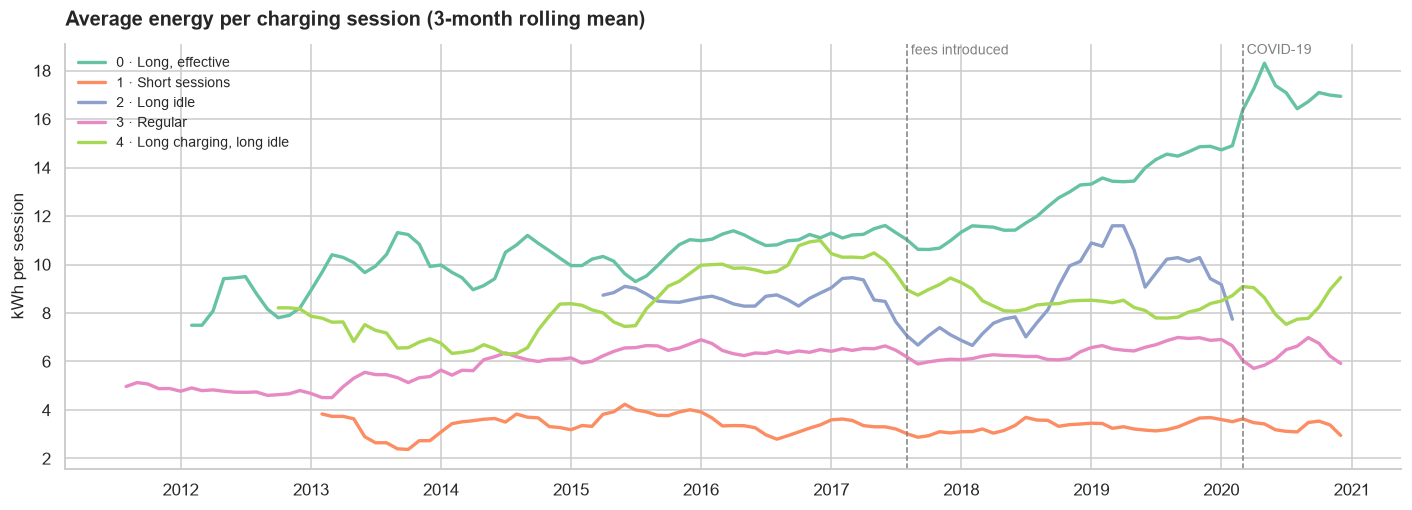

In [53]:
# 5a. average energy per session
trend_plot(wide("avg_energy_session"), "Average energy per charging session (3-month rolling mean)", "kWh per session")
plt.tight_layout()
plt.show()

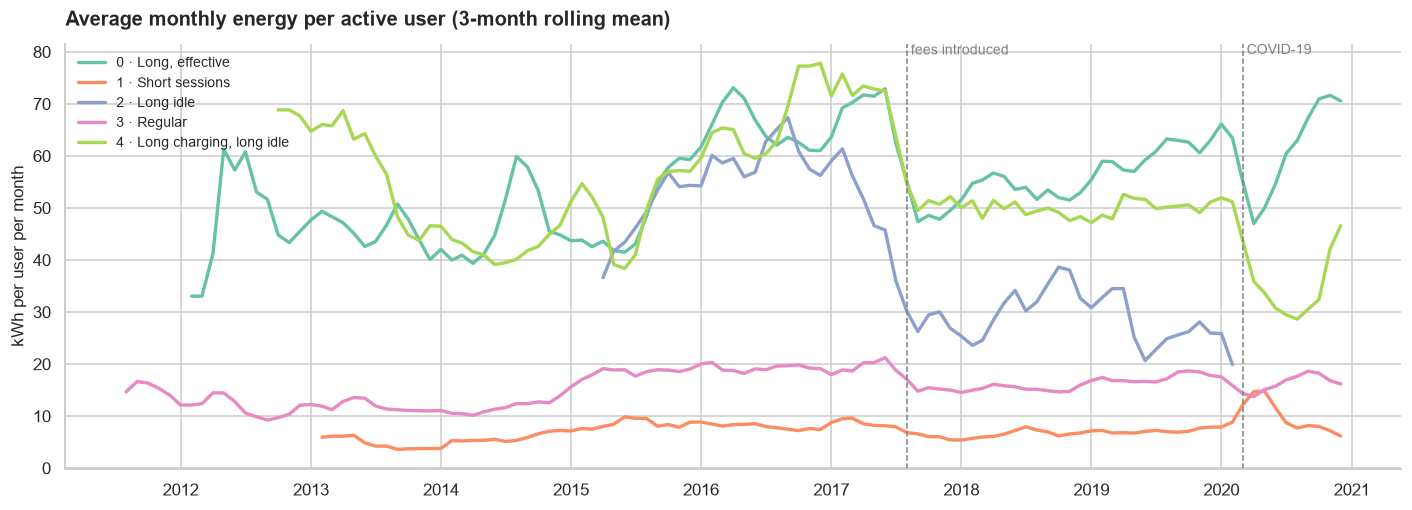

In [54]:
# 5b. average monthly energy per user
trend_plot(wide("avg_energy_user"), "Average monthly energy per active user (3-month rolling mean)", "kWh per user per month")
plt.tight_layout()
plt.show()

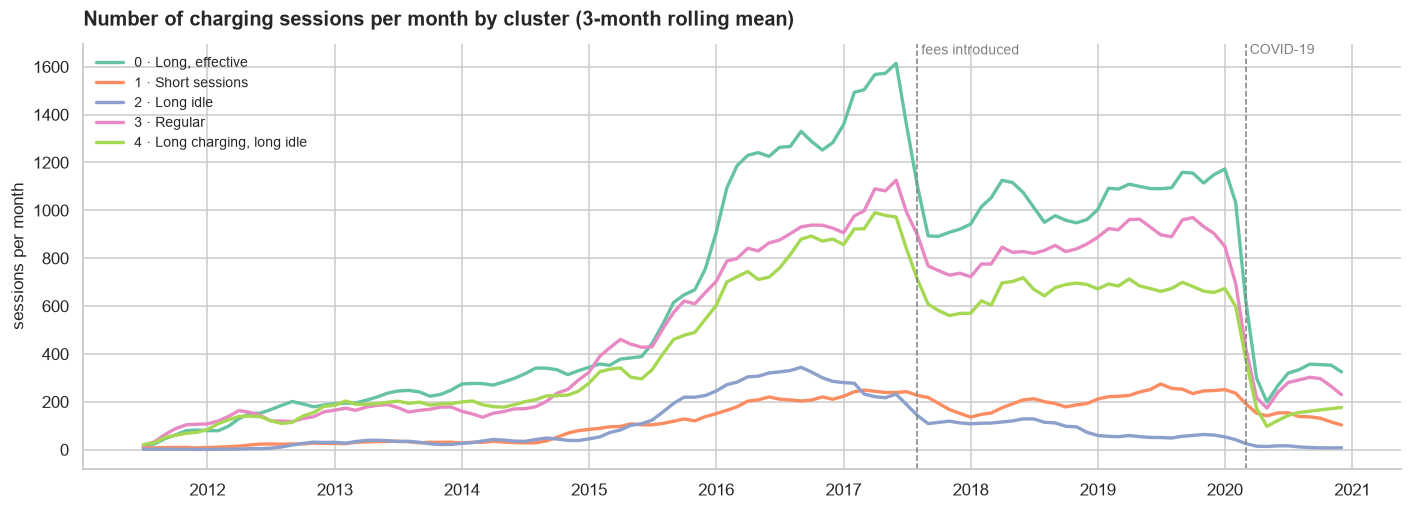

In [55]:
sessions_month = dc.groupby(["month", "Cluster"]).size().unstack("Cluster")
sessions_month = sessions_month.rolling(ROLL, min_periods=1, center=True).mean()

trend_plot(sessions_month, "Number of charging sessions per month by cluster (3-month rolling mean)",
           "sessions per month")
plt.tight_layout()
plt.show()

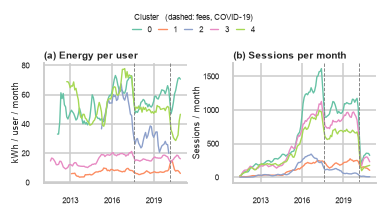

In [56]:
# plot to put on a report
import matplotlib.dates as mdates

energy_user = wide("avg_energy_user")

tiny_fonts = {"font.size": 6, "axes.titlesize": 6.5, "axes.titleweight": "bold",
              "axes.labelsize": 6, "xtick.labelsize": 5.5, "ytick.labelsize": 5.5,
              "legend.fontsize": 5.5, "axes.titlepad": 3}

with plt.rc_context(tiny_fonts):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(3.5, 1.9))

    panels = [(ax1, energy_user, "(a) Energy per user", "kWh / user / month"),
              (ax2, sessions_month, "(b) Sessions per month", "Sessions / month")]

    for ax, table, title, ylabel in panels:
        for c in CLUSTER_ORDER:
            ax.plot(table.index, table[c], lw=0.9, color=CLUSTER_COLORS[c], label=str(c))
        for date in (FEE_START, COVID_START):
            ax.axvline(date, ls="--", c="grey", lw=0.6)
        ax.set_title(title, loc="left")
        ax.set_ylabel(ylabel, labelpad=1)
        ax.set_xlabel("")
        ax.xaxis.set_major_locator(mdates.YearLocator(3))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    handles, labels = ax1.get_legend_handles_labels()
    fig.legend(handles, labels, title="Cluster   (dashed: fees, COVID-19)", ncol=5,
               loc="upper center", bbox_to_anchor=(0.5, 1.0), frameon=False,
               handlelength=1, columnspacing=0.8, title_fontsize=5.5)

    fig.tight_layout(rect=(0, 0, 1, 0.83), w_pad=0.6)
    fig.savefig("figures/cluster_trends.pdf", bbox_inches="tight")
    plt.show()

### Conclusions 

* Clusters reacted differently to fees in 2017. Number of sessions within clusters 1 and 2 remained the same while for cluster 0,3,4 we see a sharp drop in the overall number of sessions

* We see a high drop in avg evergy per user. The highest difference was for heavy clusters (0,2,4) and with comparison to the other plots it was a result of less visits on the stations. 

* For cluster 4 number of sessions remained similar but the avg energy dropped meaning those users started charging less on their sessions.

* in mid 2020 the number of sessions dropped again due to covid

* Clusters 0 and 4 were the once to start recovering the most after both drops

## 6. Overnight charging

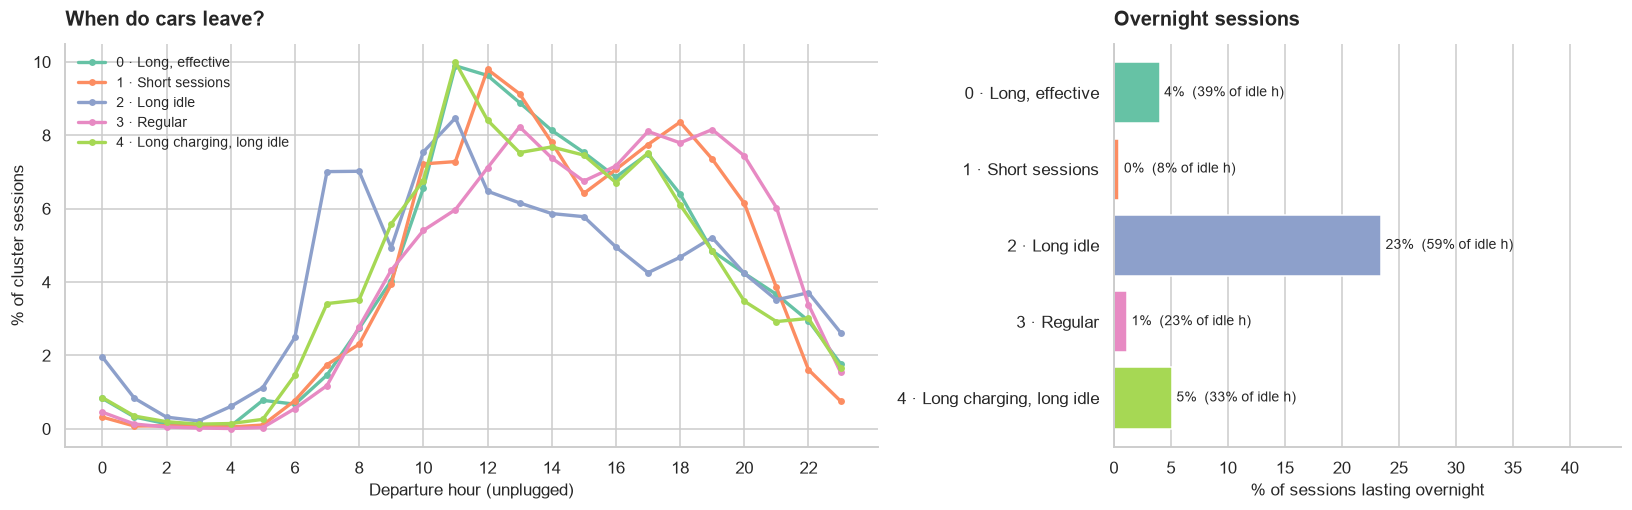

,overnight_pct,overnight_idle_share
Cluster,,
"0 · Long, effective",4.0,38.9
1 · Short sessions,0.5,8.0
2 · Long idle,23.4,59.0
3 · Regular,1.1,22.7
"4 · Long charging, long idle",5.1,33.4


In [57]:
dc["end_hour"] = dc["End Date"].dt.hour
dc["overnight"] = dc["End Date"].dt.normalize() > dc["Start Date"].dt.normalize()

departure = pd.crosstab(dc["end_hour"], dc["Cluster"], normalize="columns").reindex(range(24), fill_value=0) * 100
overnight = dc.groupby("Cluster").agg(
    overnight_pct=("overnight", lambda x: 100 * x.mean()),
    overnight_idle_share=("idle_hours", lambda x: 100 * x[dc.loc[x.index, "overnight"]].sum() / x.sum()),
)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
for c in CLUSTER_ORDER:
    axes[0].plot(departure.index, departure[c], marker="o", ms=3.5, lw=2.2,
                 color=CLUSTER_COLORS[c], label=CLUSTER_LABELS[c])
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xlabel("Departure hour (unplugged)")
axes[0].set_ylabel("% of cluster sessions")
axes[0].set_title("When do cars leave?", loc="left")
axes[0].legend(fontsize=9)

names = [CLUSTER_LABELS[c] for c in overnight.index]
b = axes[1].barh(names, overnight["overnight_pct"], color=[CLUSTER_COLORS[c] for c in overnight.index])
axes[1].bar_label(b, labels=[f"{p:.0f}%  ({s:.0f}% of idle h)" for p, s in
                             zip(overnight["overnight_pct"], overnight["overnight_idle_share"])],
                  padding=3, fontsize=9)
axes[1].set_xlim(0, overnight["overnight_pct"].max() * 1.9)
axes[1].invert_yaxis()
axes[1].set_xlabel("% of sessions lasting overnight")
axes[1].set_title("Overnight sessions", loc="left")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

display(overnight.rename(index=CLUSTER_LABELS).round(1))

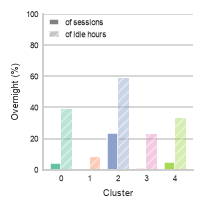

,overnight_pct,overnight_idle_share
Cluster,,
"0 · Long, effective",4.0,38.9
1 · Short sessions,0.5,8.0
2 · Long idle,23.4,59.0
3 · Regular,1.1,22.7
"4 · Long charging, long idle",5.1,33.4


In [58]:
# to put on the report
from matplotlib.patches import Patch

dc["overnight"] = dc["End Date"].dt.normalize() > dc["Start Date"].dt.normalize()
overnight = dc.groupby("Cluster").agg(
    overnight_pct=("overnight", lambda x: 100 * x.mean()),
    overnight_idle_share=("idle_hours", lambda x: 100 * x[dc.loc[x.index, "overnight"]].sum() / x.sum()),
)

PANEL_W, PANEL_H = 1.7, 1.75  
panel_fonts = {"font.size": 6, "axes.labelsize": 6, "xtick.labelsize": 5.5,
               "ytick.labelsize": 5.5, "legend.fontsize": 5.5}

x = np.arange(len(overnight))
w = 0.38

with plt.rc_context(panel_fonts):
    fig, ax = plt.subplots(figsize=(PANEL_W, PANEL_H))
    colors = [CLUSTER_COLORS[c] for c in overnight.index]
    ax.bar(x - w / 2, overnight["overnight_pct"], width=w, color=colors)
    ax.bar(x + w / 2, overnight["overnight_idle_share"], width=w, color=colors, alpha=0.45,
           hatch="////", edgecolor="white", linewidth=0)
    ax.set_xticks(x, [str(c) for c in overnight.index])
    ax.set_ylim(0, 100)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Overnight (%)")
    ax.tick_params(axis="both", length=0)
    ax.grid(axis="x", visible=False)
    ax.legend(handles=[Patch(facecolor="grey", label="of sessions"),
                       Patch(facecolor="grey", alpha=0.45, hatch="////", edgecolor="white",
                             label="of idle hours")],
              loc="upper left", frameon=False, handlelength=1.2, borderaxespad=0.2)
    fig.tight_layout(pad=0.3)
    fig.savefig("figures/overnight_by_cluster.pdf", bbox_inches="tight")
    plt.show()

display(overnight.rename(index=CLUSTER_LABELS).round(1))

### Conclusions

We confirm that many of the Cluster 2 user sessions are happening overnight, additionally a big part of idle time is the overnight charging (when there is low demand either way)

# Possible recommendations for this clustering:

1) Long idle time is mainly caused by users from cluster 2 and 4, but the problem is not directed at any specific station, but rather across the whole city. Recommendation : Send SMS reminders about the ending of charging; 

2) However, we checked that many idle hours are due to overnight charging (when demand is low either way) and after introducing fees the number of sessions for users in cluster 2 dropped and never bounced back - maybe not to loose those customers (or attract them back) due to high fees, the fees for stalling should be only for the day, when there is a risk they are in fact taking someone's place. (prepare some night offer to attract the stallers at night to unblock the chargers during the day)

3) Cluster 0 as the most valuable customers - they have the largest amount of sessions and used energy, meaning they generate the highest revenue. They are also loyal to their preferred site. Recommendation : keep those users. They charge mostly on weekday mornings - make sure to have the chargers available, penalize idle time even more during that time, introduce some yearly abonament for those regular users (on their station).

4) Clusters 0 and 4 as the most valuable user groups - (a) they are most loyal to one station: recommendation to introduce some point system/discounts for regular customers (b) they bounced back after a sharp drop of sessions after fee introduction 
